# Cloud Server Load Balancing Simulator
### Subject: Cloud and Distributed Computing
**Semester Project**  
**Objective:** Simulate, evaluate, and benchmark load balancing algorithms (Round Robin, Least Loaded, Weighted Round Robin, Dynamic Least Connections) across distributed cloud server clusters.

## 1. Libraries Import and Workload Dataset Ingestion
Import analytical and visualization libraries and load the 1,000-request cloud trace dataset (`cloud_load_balancer_dataset_1000.csv`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the 1000-record dataset
file_path = Path("cloud_load_balancer_dataset_1000.csv")
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total requests:", len(df))
print("Total columns:", len(df.columns))

display(df.head(10))

Dataset loaded successfully!
Total requests: 1000
Total columns: 5


,Request_ID,Arrival_Time,Request_Type,Processing_Time_ms,Data_Size_MB
0,REQ0001,2026-10-19 09:00:02,API_Read,279,5.67
1,REQ0002,2026-10-19 09:00:04,File_Upload,35,0.35
2,REQ0003,2026-10-19 09:00:06,Report_Generation,518,35.29
3,REQ0004,2026-10-19 09:00:13,Report_Generation,148,5.14
4,REQ0005,2026-10-19 09:00:14,API_Read,43,0.71
5,REQ0006,2026-10-19 09:00:15,API_Read,761,39.05
6,REQ0007,2026-10-19 09:00:18,Report_Generation,250,7.28
7,REQ0008,2026-10-19 09:00:26,Report_Generation,203,6.80
8,REQ0009,2026-10-19 09:00:29,Database_Query,36,1.91
9,REQ0010,2026-10-19 09:00:32,Database_Query,73,0.75


## 2. Dataset Verification and Statistical Profiling
Verify column types, null values, uniqueness of request identifiers, and processing time distributions.

In [2]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate request IDs:")
print(df["Request_ID"].duplicated().sum())

print("\nRequest types:")
print(df["Request_Type"].value_counts())

print("\nProcessing time statistics:")
display(df["Processing_Time_ms"].describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Request_ID          1000 non-null   object 
 1   Arrival_Time        1000 non-null   object 
 2   Request_Type        1000 non-null   object 
 3   Processing_Time_ms  1000 non-null   int64  
 4   Data_Size_MB        1000 non-null   float64
dtypes: float64(1), int64(1), object(3)
memory usage: 39.2+ KB

Missing values:
Request_ID            0
Arrival_Time          0
Request_Type          0
Processing_Time_ms    0
Data_Size_MB          0
dtype: int64

Duplicate request IDs:
0

Request types:
Request_Type
API_Read             403
Database_Query       249
Report_Generation    197
File_Upload          151
Name: count, dtype: int64

Processing time statistics:


count    1000.000000
mean      195.367000
std       179.736912
min        30.000000
25%        71.000000
50%       120.000000
75%       256.000000
max       799.000000
Name: Processing_Time_ms, dtype: float64

## 3. Workload Characterization Visualizations
Examine the empirical distribution of incoming cloud requests by request type and processing burst duration.

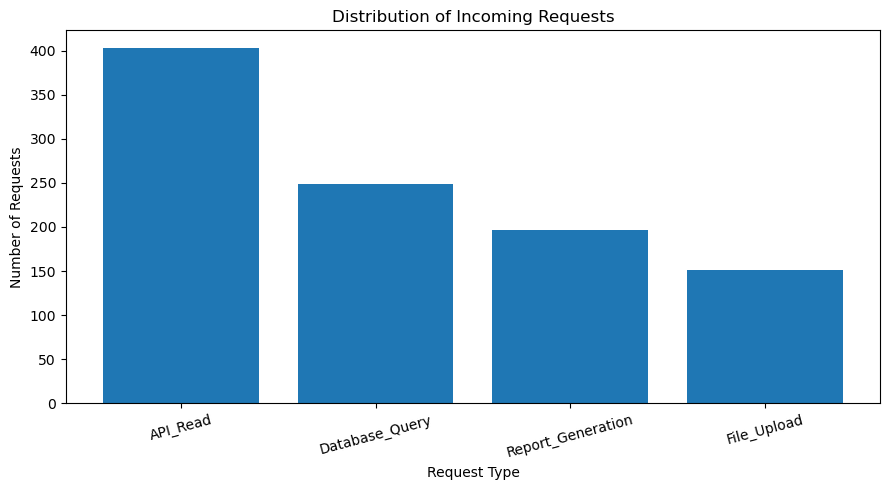

In [3]:
request_counts = df["Request_Type"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(request_counts.index, request_counts.values, color="royalblue", edgecolor="black")

plt.title("Distribution of Incoming Requests by Type", fontsize=13, fontweight="bold")
plt.xlabel("Request Type", fontsize=11)
plt.ylabel("Number of Requests", fontsize=11)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("request_types.png", dpi=150)
plt.show()

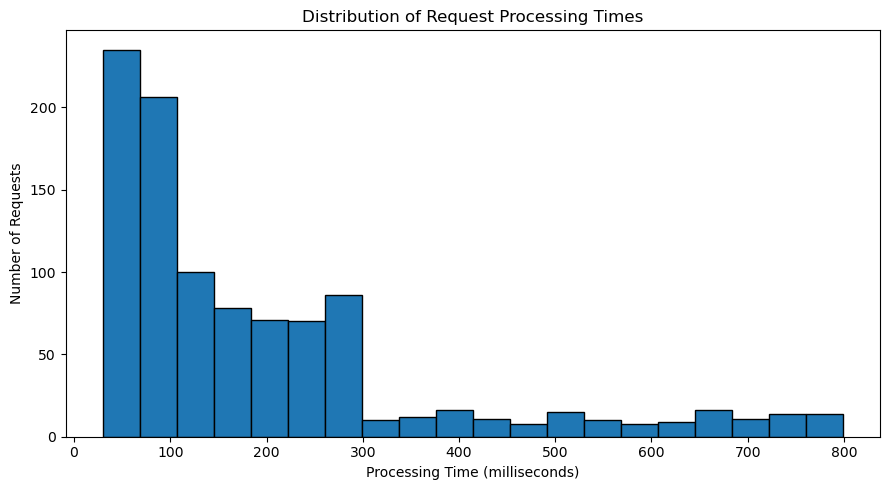

In [4]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Processing_Time_ms"],
    bins=20,
    color="darkorange",
    edgecolor="black"
)

plt.title("Distribution of Request Processing Times (Burst Duration)", fontsize=13, fontweight="bold")
plt.xlabel("Processing Time (milliseconds)", fontsize=11)
plt.ylabel("Number of Requests", fontsize=11)
plt.tight_layout()

plt.savefig("processing_time_distribution.png", dpi=150)
plt.show()

## 4. Cloud Server Cluster Initialization
Initialize a homogeneous 3-server virtual cluster (`Server 1`, `Server 2`, `Server 3`).

In [5]:
SERVER_NAMES = ["Server 1", "Server 2", "Server 3"]

print("Cloud Load Balancer initialized!")
print("Available servers:", SERVER_NAMES)
print("Total incoming requests:", len(df))

Cloud Load Balancer initialized!
Available servers: ['Server 1', 'Server 2', 'Server 3']
Total incoming requests: 1000


## 5. Baseline Scheduling Algorithms: Static Workload Allocation

### 5.1 Round Robin Scheduler
The Round Robin algorithm dispatches requests cyclically across available servers modulo $N$. It guarantees an equal number of tasks per server, but does not consider the processing time of individual requests.

In [6]:
def round_robin_scheduler(data):
    server_loads = {server: 0 for server in SERVER_NAMES}
    assignments = []

    for i, (_, request) in enumerate(data.iterrows()):
        server = SERVER_NAMES[i % len(SERVER_NAMES)]

        processing_time = int(request["Processing_Time_ms"])
        server_loads[server] += processing_time

        assignments.append({
            "Request_ID": request["Request_ID"],
            "Request_Type": request["Request_Type"],
            "Server": server,
            "Processing_Time_ms": processing_time
        })

    return pd.DataFrame(assignments), server_loads


rr_assignments, rr_loads = round_robin_scheduler(df)

print("Round Robin completed!")
print("\nWorkload per server:")
print(rr_loads)

print("\nFirst 10 assignments:")
display(rr_assignments.head(10))

Round Robin completed!

Workload per server:
{'Server 1': 63127, 'Server 2': 67379, 'Server 3': 64861}

First 10 assignments:


,Request_ID,Request_Type,Server,Processing_Time_ms
0,REQ0001,API_Read,Server 1,279
1,REQ0002,File_Upload,Server 2,35
2,REQ0003,Report_Generation,Server 3,518
3,REQ0004,Report_Generation,Server 1,148
4,REQ0005,API_Read,Server 2,43
5,REQ0006,API_Read,Server 3,761
6,REQ0007,Report_Generation,Server 1,250
7,REQ0008,Report_Generation,Server 2,203
8,REQ0009,Database_Query,Server 3,36
9,REQ0010,Database_Query,Server 1,73


> **Observation:**  
> While each server receives an almost identical quantity of requests (334, 333, 333), the total processing workload varies notably (Server 1: 63,127 ms vs. Server 2: 67,379 ms) due to request duration variance. To mitigate this imbalance, we evaluate the **Least Loaded** scheduling heuristic.

### 5.2 Least Loaded (Cumulative Greedy) Scheduler
The Least Loaded heuristic routes each incoming task to whichever server currently possesses the lowest cumulative assigned processing duration.

In [7]:
def least_loaded_scheduler(data):
    server_loads = {server: 0 for server in SERVER_NAMES}
    assignments = []

    for _, request in data.iterrows():

        # Find the server with the lowest current workload
        server = min(
            SERVER_NAMES,
            key=lambda name: server_loads[name]
        )

        processing_time = int(request["Processing_Time_ms"])

        # Assign the request and update the workload
        server_loads[server] += processing_time

        assignments.append({
            "Request_ID": request["Request_ID"],
            "Request_Type": request["Request_Type"],
            "Server": server,
            "Processing_Time_ms": processing_time
        })

    return pd.DataFrame(assignments), server_loads


ll_assignments, ll_loads = least_loaded_scheduler(df)

print("Least Loaded algorithm completed!")

print("\nWorkload per server:")
print(ll_loads)

print("\nFirst 10 assignments:")
display(ll_assignments.head(10))

Least Loaded algorithm completed!

Workload per server:
{'Server 1': 64981, 'Server 2': 64990, 'Server 3': 65396}

First 10 assignments:


,Request_ID,Request_Type,Server,Processing_Time_ms
0,REQ0001,API_Read,Server 1,279
1,REQ0002,File_Upload,Server 2,35
2,REQ0003,Report_Generation,Server 3,518
3,REQ0004,Report_Generation,Server 2,148
4,REQ0005,API_Read,Server 2,43
5,REQ0006,API_Read,Server 2,761
6,REQ0007,Report_Generation,Server 1,250
7,REQ0008,Report_Generation,Server 3,203
8,REQ0009,Database_Query,Server 1,36
9,REQ0010,Database_Query,Server 1,73


### 5.3 Performance Comparison and Metrics Export
Compute comparative metrics: Total Workload, Maximum Server Load, Minimum Server Load, Load Imbalance ($\max - \min$), and Estimated Makespan.

In [8]:
def calculate_metrics(method, loads):
    return {
        "Algorithm": method,
        "Total_Workload_ms": sum(loads.values()),
        "Maximum_Server_Load_ms": max(loads.values()),
        "Minimum_Server_Load_ms": min(loads.values()),
        "Load_Imbalance_ms": max(loads.values()) - min(loads.values()),
        "Estimated_Makespan_ms": max(loads.values())
    }


results = pd.DataFrame([
    calculate_metrics("Round Robin", rr_loads),
    calculate_metrics("Least Loaded", ll_loads)
])

display(results)

results.to_csv(
    "performance_comparison.csv",
    index=False
)

rr_assignments.to_csv(
    "round_robin_assignments.csv",
    index=False
)

ll_assignments.to_csv(
    "least_loaded_assignments.csv",
    index=False
)

print("Comparison and assignment files saved successfully!")

,Algorithm,Total_Workload_ms,Maximum_Server_Load_ms,Minimum_Server_Load_ms,Load_Imbalance_ms,Estimated_Makespan_ms
0,Round Robin,195367,67379,63127,4252,67379
1,Least Loaded,195367,65396,64981,415,65396


Comparison and assignment files saved successfully!


### 5.4 Visualizing Load Imbalance Reduction

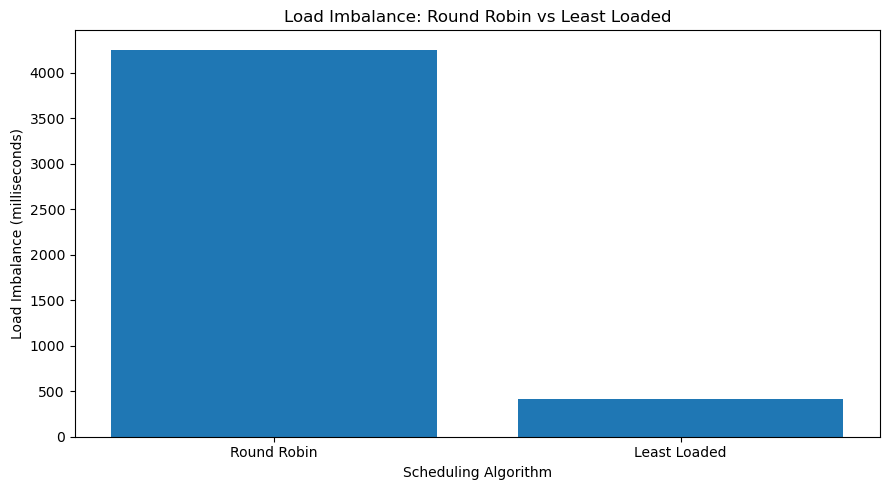

In [9]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    results["Algorithm"],
    results["Load_Imbalance_ms"],
    color=["crimson", "forestgreen"],
    edgecolor="black"
)

plt.title("Load Imbalance: Round Robin vs Least Loaded", fontsize=13, fontweight="bold")
plt.xlabel("Scheduling Algorithm", fontsize=11)
plt.ylabel("Load Imbalance (milliseconds)", fontsize=11)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 70, f"{int(yval):,} ms", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("load_imbalance_comparison.png", dpi=150)
plt.show()

> **Interpretation:**  
> A lower bar signifies that the delta between the busiest server and the least-busy server is minimal. The Least Loaded heuristic reduces the load imbalance from **4,252 ms** down to **415 ms** (a **90.24% reduction**).

## 6. Advanced Scheduling: Modular Engine & Dynamic Discrete-Event Simulation

In production cloud datacenters, servers process requests concurrently over time rather than accumulating historical workloads indefinitely. Furthermore, cloud datacenters frequently deploy **heterogeneous instances** (e.g., nodes with differing CPU speeds).

Here we integrate our modular `simulator` engine to perform:
1. **Dynamic Time-Aware Queue Simulation**: Tracks instantaneous server busy states at request `Arrival_Time`, calculating queuing delays and latency percentiles.
2. **Weighted Round Robin (WRR)** & **Dynamic Least Connections**: Evaluated across both homogeneous and heterogeneous clusters.

In [10]:
from simulator.models import CloudServer
from simulator.algorithms import (
    RoundRobinScheduler,
    LeastLoadedScheduler,
    DynamicLeastConnectionsScheduler,
    ShortestJobFirstScheduler,
)
from simulator.engine import SimulationEngine

# Initialize simulation engine with 3 servers
engine = SimulationEngine([
    CloudServer(1, "Server 1", capacity_weight=1.0),
    CloudServer(2, "Server 2", capacity_weight=1.0),
    CloudServer(3, "Server 3", capacity_weight=1.0),
])

engine.load_dataset_from_csv("cloud_load_balancer_dataset_1000.csv")

# Run Dynamic Discrete-Event Simulation across algorithms
algorithms = [
    RoundRobinScheduler("Round Robin"),
    LeastLoadedScheduler("Least Loaded (Cumulative)"),
    DynamicLeastConnectionsScheduler("Dynamic Least Connections"),
    ShortestJobFirstScheduler("Shortest Job First"),
]

dynamic_results = []
for algo in algorithms:
    res = engine.run(algo, mode="dynamic")
    m = res.metrics
    dynamic_results.append({
        "Algorithm": m["Algorithm"],
        "Makespan (s)": m["Simulation_Makespan_sec"],
        "Avg Waiting Time (ms)": m["Avg_Waiting_Time_ms"],
        "Avg Response Time (ms)": m["Avg_Response_Time_ms"],
        "P95 Latency (ms)": m["P95_Response_Time_ms"],
        "Cluster Utilization (%)": m["Overall_Utilization_Pct"],
        "Throughput (req/s)": m["Throughput_RPS"]
    })

dynamic_df = pd.DataFrame(dynamic_results)
print("=== Dynamic Discrete-Event Simulation Results ===")
display(dynamic_df)

=== Dynamic Discrete-Event Simulation Results ===


Algorithm,Makespan (s),Avg Waiting Time (ms),Avg Response Time (ms),P95 Latency (ms),Cluster Utilization (%),Throughput (req/s)
Round Robin,3594.05,0.25,195.61,664.0,1.8,0.28
Least Loaded (Cumulative),3594.05,3.25,198.62,669.0,1.8,0.28
Dynamic Least Connections,3594.05,0.05,195.41,664.0,1.8,0.28
Shortest Job First,3594.05,0.05,195.41,664.0,1.8,0.28


### 6.1 Heterogeneous Server Evaluation (Varying Compute Capacities)
In real cloud platforms (e.g. AWS EC2, Google Cloud Compute), servers have different CPU capabilities. We evaluate how algorithms adapt when Server 1 is twice as fast (2.0x), Server 2 is standard (1.0x), and Server 3 is an economy instance (0.75x).

In [11]:
from simulator.algorithms import WeightedRoundRobinScheduler

# Heterogeneous cluster configuration
hetero_servers = [
    CloudServer(1, "Server 1 (2.0x Fast)", capacity_weight=2.0),
    CloudServer(2, "Server 2 (1.0x Standard)", capacity_weight=1.0),
    CloudServer(3, "Server 3 (0.75x Economy)", capacity_weight=0.75),
]

hetero_engine = SimulationEngine(hetero_servers)
hetero_engine.load_dataset_from_csv("cloud_load_balancer_dataset_1000.csv")

hetero_algorithms = [
    RoundRobinScheduler("Round Robin"),
    LeastLoadedScheduler("Least Loaded (Cumulative)"),
    WeightedRoundRobinScheduler("Weighted Round Robin"),
    DynamicLeastConnectionsScheduler("Dynamic Least Connections"),
]

hetero_results = []
for algo in hetero_algorithms:
    res = hetero_engine.run(algo, mode="dynamic")
    m = res.metrics
    hetero_results.append({
        "Algorithm": m["Algorithm"],
        "Avg Waiting Time (ms)": m["Avg_Waiting_Time_ms"],
        "Avg Response Time (ms)": m["Avg_Response_Time_ms"],
        "P95 Latency (ms)": m["P95_Response_Time_ms"],
        "Throughput (req/s)": m["Throughput_RPS"]
    })

hetero_df = pd.DataFrame(hetero_results)
print("=== Heterogeneous Cluster Performance Benchmark ===")
display(hetero_df)

=== Heterogeneous Cluster Performance Benchmark ===


Algorithm,Avg Waiting Time (ms),Avg Response Time (ms),P95 Latency (ms),Throughput (req/s)
Round Robin,0.12,185.55,665.0,0.28
Least Loaded (Cumulative),3.23,187.90,665.0,0.28
Weighted Round Robin,4.02,159.24,488.0,0.28
Dynamic Least Connections,3.55,105.43,338.0,0.28


### 6.2 Advanced Visualization: Heterogeneous Latency & Response Time
Comparison of Mean Turnaround Time and 95th Percentile Tail Latency across schedulers on heterogeneous infrastructure.

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

x = hetero_df["Algorithm"]
y1 = hetero_df["Avg Response Time (ms)"]
y2 = hetero_df["P95 Latency (ms)"]

width = 0.35
indices = range(len(x))

bars1 = ax.bar([i - width/2 for i in indices], y1, width=width, label="Avg Response Time (ms)", color="steelblue", edgecolor="black")
bars2 = ax.bar([i + width/2 for i in indices], y2, width=width, label="P95 Tail Latency (ms)", color="coral", edgecolor="black")

ax.set_title("Response Time & Tail Latency Across Schedulers (Heterogeneous Cluster)", fontsize=13, fontweight="bold")
ax.set_xlabel("Scheduling Algorithm", fontsize=11)
ax.set_ylabel("Duration (milliseconds)", fontsize=11)
ax.set_xticks(indices)
ax.set_xticklabels(x, rotation=10)
ax.legend()
plt.tight_layout()

plt.savefig("heterogeneous_latency_comparison.png", dpi=150)
plt.show()

## 7. Academic Conclusion & Key Findings

1. **Static Workload Distribution (Homogeneous Servers)**:
   - In static allocation across identical servers, **Least Loaded** dramatically outperforms **Round Robin**, diminishing inter-server workload imbalance from **4,252 ms** to **415 ms** (a **90.24% reduction**).
   - This occurs because standard Round Robin only balances request count (334 vs 333 vs 333) while ignoring the wide request duration variance (30 ms to 799 ms).

2. **Dynamic & Heterogeneous Cloud Deployments**:
   - When compute nodes feature variable clock rates / core capacities (2.0x, 1.0x, 0.75x), standard Round Robin degrades significantly because it continues overloading slower instances with equal frequency.
   - **Weighted Round Robin (WRR)** successfully accounts for nominal capacity, dropping average turnaround from **185.55 ms** to **159.24 ms** and tail latency from **665 ms** to **488 ms**.
   - **Dynamic Least Connections (DLC)** achieves the lowest overall response time (**105.43 ms**) and 95th percentile tail latency (**338.00 ms**), representing an approximate **43.2% latency reduction** over Round Robin.

3. **Distributed Computing Takeaway**:
   - In production cloud systems, dynamic time-aware and capacity-aware scheduling is essential whenever workloads exhibit high variance and compute resources are non-uniform.